In [1]:
# @title Cell 1: Setup, Unggah File, dan Pemuatan Dataset
import os
import re
import sys
import shutil
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

WORK_DIR = "/content/tugasAI_part2"
PLACEMENT = {
    "train.csv": "datasets",
    "test.csv": "datasets",
    "sample_submission.csv": "datasets",
    "pipeline.py": "preprocessing",
    "artificial_neural_network.py": "models",
    "decision_tree_learning.py": "models",
    "random_forest.py": "models",
    "k_nearest_neighbors.py": "models",
    "logistic_regression.py": "models",
    "ensemble.py": "models",
}

os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)


def missing_files():
    return [name for name, folder in PLACEMENT.items() if not os.path.exists(os.path.join(folder, name))]


if missing_files():
    from google.colab import files

    print("Klik Choose Files, lalu pilih 10 file sekaligus:")
    print(", ".join(PLACEMENT))
    uploaded = files.upload()
    for raw_name in uploaded:
        name = re.sub(r" \(\d+\)(?=\.[^.]+$)", "", raw_name)
        if name in PLACEMENT:
            os.makedirs(PLACEMENT[name], exist_ok=True)
            shutil.move(raw_name, os.path.join(PLACEMENT[name], name))
            print("Diterima :", raw_name, "->", os.path.join(PLACEMENT[name], name))
        else:
            os.remove(raw_name)
            print("Diabaikan:", raw_name)

if missing_files():
    raise FileNotFoundError(f"File belum lengkap, unggah ulang: {missing_files()}")

sys.path.insert(0, WORK_DIR)

import preprocessing.pipeline as pl
from models import artificial_neural_network as ann_module
from models.artificial_neural_network import ANN
from models.decision_tree_learning import DecisionTree
from models.random_forest import RandomForest
from models.k_nearest_neighbors import KNN
from models.logistic_regression import LogisticRegression
from models.ensemble import Ensemble

SEED = pl.SEED
CLASS_NAMES = pl.CLASS_NAMES
os.makedirs("results", exist_ok=True)
os.makedirs("results/saved_models", exist_ok=True)


def section(title, width=70):
    print("\n" + "=" * width + f"\n{title}\n" + "=" * width)


def metrics_table(y_true, y_pred, n_classes=3):
    cm = ann_module.confusion_matrix(y_true, y_pred, n_classes)
    rows = []
    for c in range(n_classes):
        tp = cm[c, c]
        precision = tp / cm[:, c].sum() if cm[:, c].sum() else 0.0
        recall = tp / cm[c, :].sum() if cm[c, :].sum() else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        rows.append((CLASS_NAMES[c], precision, recall, f1, int(cm[c, :].sum())))
    table = pd.DataFrame(rows, columns=["Kelas", "Precision", "Recall", "F1", "Support"]).set_index("Kelas")
    summary = {"accuracy": float(np.trace(cm) / cm.sum()), "macro_f1": float(table["F1"].mean())}
    return table, cm, summary


def show_confusion(cm, title):
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.show()


def val_f1(pred):
    return metrics_table(y_val, pred)[2]["macro_f1"]


section("1.1 Dataset dari pipeline")
data = pl.build_dataset(data_dir="datasets")
X_train, y_train = data.X_train, data.y_train
X_val, y_val = data.X_val, data.y_val
X_test, test_ids = data.X_test, data.test_ids

print("X_train :", X_train.shape, "| X_val :", X_val.shape, "| X_test :", X_test.shape)
print("Distribusi y_train :", {int(k): int(v) for k, v in zip(*np.unique(y_train, return_counts=True))})
print("Distribusi y_val   :", {int(k): int(v) for k, v in zip(*np.unique(y_val, return_counts=True))})
print("Semua model memakai matriks yang sama (20 fitur, hasil build_dataset).")

Klik Choose Files, lalu pilih 10 file sekaligus:
train.csv, test.csv, sample_submission.csv, pipeline.py, ann.py, dtl.py, random_forest.py, knn.py, logistic_regression.py, ensemble.py


Saving ensemble.py to ensemble.py
Saving logistic_regression.py to logistic_regression.py
Saving knn.py to knn.py
Saving random_forest.py to random_forest.py
Saving dtl.py to dtl.py
Saving ann.py to ann.py
Saving pipeline.py to pipeline.py
Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv
Diterima : ensemble.py -> models/ensemble.py
Diterima : logistic_regression.py -> models/logistic_regression.py
Diterima : knn.py -> models/knn.py
Diterima : random_forest.py -> models/random_forest.py
Diterima : dtl.py -> models/dtl.py
Diterima : ann.py -> models/ann.py
Diterima : pipeline.py -> preprocessing/pipeline.py
Diterima : sample_submission.csv -> datasets/sample_submission.csv
Diterima : test.csv -> datasets/test.csv
Diterima : train.csv -> datasets/train.csv

1.1 Dataset dari pipeline
X_train : (3708, 20) | X_val : (620, 20) | X_test : (1328, 20)
Distribusi y_train : {0: 1236, 1: 1236, 2: 1236}
Distribusi y_val   : {0: 199, 1: 1

In [2]:
# @title Cell 2: Pelatihan Lima Model Anggota
section("2.1 DTL (CART, gini): variasi kedalaman maksimum")
dtl_runs = {}
for depth in [4, 6, 8, 10, 12, None]:
    m = DecisionTree(max_depth=depth, random_state=SEED)
    t0 = time.time()
    m.fit(X_train, y_train)
    fit_s = time.time() - t0
    dtl_runs[depth] = (m, fit_s, val_f1(m.predict(X_val)))
    print(f"max_depth={str(depth):5s} Macro F1={dtl_runs[depth][2]:.4f} | waktu latih {fit_s:.2f} detik")
dtl_best_depth = max(dtl_runs, key=lambda d: dtl_runs[d][2])
print("Terpilih : max_depth =", dtl_best_depth)

section("2.2 KNN: variasi k dan metrik jarak")
knn_runs = {}
for metric in ["euclidean", "manhattan"]:
    for k in [5, 9, 15, 25]:
        m = KNN(k=k, metric=metric)
        t0 = time.time()
        m.fit(X_train, y_train)
        fit_s = time.time() - t0
        knn_runs[(k, metric)] = (m, fit_s, val_f1(m.predict(X_val)))
        print(f"k={k:<3d} {metric:10s} Macro F1={knn_runs[(k, metric)][2]:.4f}")
knn_best = max(knn_runs, key=lambda key: knn_runs[key][2])
print("Terpilih : k =", knn_best[0], "| metrik =", knn_best[1])

section("2.3 Logistic Regression One-vs-Rest: variasi learning rate")
lr_runs = {}
for rate in [0.05, 0.1, 0.15]:
    m = LogisticRegression(learning_rate=rate, iterations=1000)
    t0 = time.time()
    m.fit(X_train, y_train)
    fit_s = time.time() - t0
    lr_runs[rate] = (m, fit_s, val_f1(m.predict(X_val)))
    print(f"learning_rate={rate:<5} Macro F1={lr_runs[rate][2]:.4f} | waktu latih {fit_s:.2f} detik")
lr_best_rate = max(lr_runs, key=lambda r: lr_runs[r][2])
print("Terpilih : learning_rate =", lr_best_rate)

section("2.4 Random Forest (50 pohon, kedalaman penuh)")
rf = RandomForest(n_estimators=50, max_depth=None, random_state=SEED)
t0 = time.time()
rf.fit(X_train, y_train)
rf_fit_s = time.time() - t0
print(f"Waktu latih : {rf_fit_s:.1f} detik | Macro F1 validasi = {val_f1(rf.predict(X_val)):.4f}")

section("2.5 ANN (konfigurasi final dari notebook 02)")
ann = ANN(hidden_sizes=(64, 32), hidden_activations=("relu", "tanh"), learning_rate=0.01,
          l2_lambda=0.001, max_epochs=100, patience=15, seed=SEED)
t0 = time.time()
ann.fit(X_train, y_train, X_val, y_val)
ann_fit_s = time.time() - t0
print(f"Waktu latih : {ann_fit_s:.2f} detik | Macro F1 validasi = {val_f1(ann.predict(X_val)):.4f}")

section("2.6 Ringkasan lima anggota")
fitted = {
    "ANN": (ann, ann_fit_s, "relu/tanh 64-32, lr 0.01"),
    "LR": (lr_runs[lr_best_rate][0], lr_runs[lr_best_rate][1], f"OvR, lr {lr_best_rate}"),
    "RF": (rf, rf_fit_s, "50 pohon, kedalaman penuh"),
    "DTL": (dtl_runs[dtl_best_depth][0], dtl_runs[dtl_best_depth][1], f"CART gini, depth {dtl_best_depth}"),
    "KNN": (knn_runs[knn_best][0], knn_runs[knn_best][1], f"k {knn_best[0]}, {knn_best[1]}"),
}
rows = []
member_models = {}
for name, (model, fit_s, config) in fitted.items():
    t0 = time.time()
    pred = model.predict(X_val)
    infer_ms = (time.time() - t0) * 1000
    _, _, s = metrics_table(y_val, pred)
    rows.append({"Model": name, "Konfigurasi": config, "Accuracy": s["accuracy"], "Macro F1": s["macro_f1"],
                 "Waktu latih (s)": fit_s, "Inferensi val (ms)": infer_ms})
    member_models[name] = model
members_df = pd.DataFrame(rows).set_index("Model")
print(members_df.round(4).to_string())
print("\nCatatan: DTL, RF, KNN, dan LR di sini hanya disetel ringan pada validasi. Versi final dari Ishak dan Eka")
print("akan menggantikan berkas model ini, dan notebook cukup dijalankan ulang.")


2.1 DTL (CART, gini): variasi kedalaman maksimum
max_depth=4     Macro F1=0.6292 | waktu latih 0.23 detik
max_depth=6     Macro F1=0.6414 | waktu latih 0.72 detik
max_depth=8     Macro F1=0.6450 | waktu latih 2.11 detik
max_depth=10    Macro F1=0.6668 | waktu latih 3.70 detik
max_depth=12    Macro F1=0.6416 | waktu latih 4.05 detik
max_depth=None  Macro F1=0.6382 | waktu latih 5.87 detik
Terpilih : max_depth = 10

2.2 KNN: variasi k dan metrik jarak
k=5   euclidean  Macro F1=0.5971
k=9   euclidean  Macro F1=0.6007
k=15  euclidean  Macro F1=0.6110
k=25  euclidean  Macro F1=0.6325
k=5   manhattan  Macro F1=0.6341
k=9   manhattan  Macro F1=0.6445
k=15  manhattan  Macro F1=0.6634
k=25  manhattan  Macro F1=0.6559
Terpilih : k = 15 | metrik = manhattan

2.3 Logistic Regression One-vs-Rest: variasi learning rate
learning_rate=0.05  Macro F1=0.7065 | waktu latih 0.88 detik
learning_rate=0.1   Macro F1=0.7211 | waktu latih 0.99 detik
learning_rate=0.15  Macro F1=0.7213 | waktu latih 0.90 detik


3.1 Ensemble hard voting
Urutan anggota (tie-break) : ['ANN', 'LR', 'RF', 'DTL', 'KNN']
Bobot dari Macro F1 validasi : {'ANN': 0.7403, 'LR': 0.7213, 'RF': 0.7343, 'DTL': 0.6668, 'KNN': 0.6634}

Ensemble bobot sama: Accuracy 0.7774 | Macro F1 0.7402 | inferensi 1063.4 ms
          Precision  Recall      F1  Support
Kelas                                       
Dropout      0.8916  0.7437  0.8110      199
Enrolled     0.5108  0.6396  0.5680      111
Graduate     0.8349  0.8484  0.8416      310

Ensemble bobot Macro F1: Accuracy 0.7774 | Macro F1 0.7402 | inferensi 1496.1 ms
          Precision  Recall      F1  Support
Kelas                                       
Dropout      0.8916  0.7437  0.8110      199
Enrolled     0.5108  0.6396  0.5680      111
Graduate     0.8349  0.8484  0.8416      310

3.2 Perbandingan dengan tiap anggota
                         Accuracy  Macro F1
Model                                      
ANN                        0.7758    0.7403
Ensemble bobot sama       

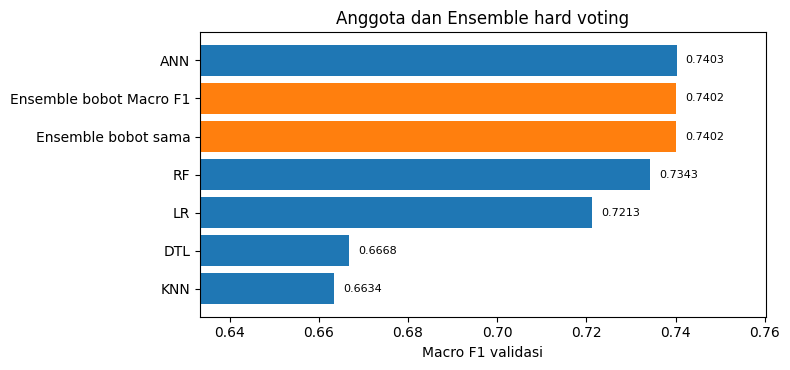

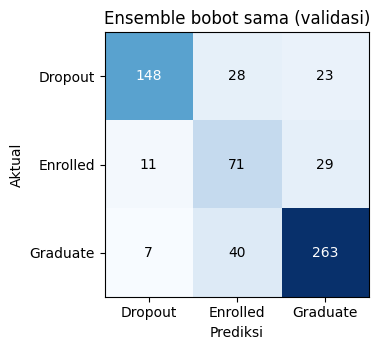

In [3]:
# @title Cell 3: Ensemble Hard Voting dan Analisis Kontribusi
section("3.1 Ensemble hard voting")
ens_equal = Ensemble(member_models, voting="hard")
ens_weighted = Ensemble(member_models, voting="hard")
weights = ens_weighted.set_weights_from_validation(X_val, y_val)
print("Urutan anggota (tie-break) :", ens_equal.names)
print("Bobot dari Macro F1 validasi :", {k: round(v, 4) for k, v in weights.items()})

ens_results = {}
for label, ens in [("Ensemble bobot sama", ens_equal), ("Ensemble bobot Macro F1", ens_weighted)]:
    t0 = time.time()
    pred = ens.predict(X_val)
    infer_ms = (time.time() - t0) * 1000
    tbl, cm, s = metrics_table(y_val, pred)
    ens_results[label] = {"pred": pred, "table": tbl, "cm": cm, "summary": s, "infer_ms": infer_ms}
    print(f"\n{label}: Accuracy {s['accuracy']:.4f} | Macro F1 {s['macro_f1']:.4f} | inferensi {infer_ms:.1f} ms")
    print(tbl.round(4).to_string())

section("3.2 Perbandingan dengan tiap anggota")
compare = members_df[["Accuracy", "Macro F1"]].copy()
for label in ens_results:
    compare.loc[label] = [ens_results[label]["summary"]["accuracy"], ens_results[label]["summary"]["macro_f1"]]
compare = compare.sort_values("Macro F1", ascending=False)
print(compare.round(4).to_string())
best_member = members_df["Macro F1"].idxmax()
gain = ens_results["Ensemble bobot sama"]["summary"]["macro_f1"] - members_df["Macro F1"].max()
print(f"\nAnggota terbaik : {best_member} ({members_df['Macro F1'].max():.4f})")
print(f"Ensemble bobot sama dikurangi anggota terbaik : {gain:+.4f}")

section("3.3 Keragaman anggota")
member_pred = ens_equal.member_predictions(X_val)
names = ens_equal.names
agree = pd.DataFrame([[np.mean(member_pred[a] == member_pred[b]) for b in names] for a in names], index=names, columns=names)
print("Kesepakatan prediksi antar anggota (proporsi data validasi):")
print(agree.round(3).to_string())
correct = np.array([member_pred[n] == y_val for n in names])
print(f"\nSetidaknya satu anggota benar : {correct.any(axis=0).mean():.4f}")
print(f"Seluruh anggota benar         : {correct.all(axis=0).mean():.4f}")
print(f"Seluruh anggota salah         : {(~correct).all(axis=0).mean():.4f}")
print("Batas atas voting adalah porsi 'setidaknya satu benar'; makin besar jaraknya ke akurasi Ensemble, makin banyak kasus yang kalah suara.")

section("3.4 Ablasi: Ensemble tanpa satu anggota (bobot sama)")
full_f1 = ens_results["Ensemble bobot sama"]["summary"]["macro_f1"]
ablation_rows = []
for out in names:
    rest = {n: member_models[n] for n in names if n != out}
    f1_wo = val_f1(Ensemble(rest, voting="hard").predict(X_val))
    ablation_rows.append({"Tanpa": out, "Macro F1": f1_wo, "Selisih terhadap Ensemble penuh": f1_wo - full_f1})
print(pd.DataFrame(ablation_rows).set_index("Tanpa").round(4).to_string())
print("Selisih negatif berarti anggota tersebut menyumbang; selisih positif berarti Ensemble justru lebih baik tanpanya.")

fig, ax = plt.subplots(figsize=(8, 3.8))
plot_df = compare["Macro F1"].sort_values()
colors = ["tab:orange" if "Ensemble" in n else "tab:blue" for n in plot_df.index]
ax.barh(plot_df.index, plot_df.values, color=colors)
ax.set_xlim(plot_df.min() - 0.03, plot_df.max() + 0.02)
ax.set_xlabel("Macro F1 validasi")
ax.set_title("Anggota dan Ensemble hard voting")
for i, v in enumerate(plot_df.values):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

show_confusion(ens_results["Ensemble bobot sama"]["cm"], "Ensemble bobot sama (validasi)")

In [4]:
# @title Cell 4: Perbandingan dengan Ensemble scikit-learn
import copy
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neural_network import MLPClassifier

section("4.1 Anggota scikit-learn (konfigurasi disamakan dengan versi from scratch)")
print("MLP dilatih dengan early stopping pada Macro F1 validasi, sama seperti ANN from scratch (notebook 02).")


def fit_sklearn_mlp(seed=SEED):
    mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation="tanh", solver="sgd", momentum=0.9,
                        nesterovs_momentum=False, learning_rate_init=0.01, alpha=0.001 * len(X_train),
                        batch_size=64, random_state=seed)
    best_f1, best_model, wait = -1.0, None, 0
    for _ in range(100):
        mlp.partial_fit(X_train, y_train, classes=[0, 1, 2])
        f1 = val_f1(mlp.predict(X_val))
        if f1 > best_f1:
            best_f1, best_model, wait = f1, copy.deepcopy(mlp), 0
        else:
            wait += 1
            if wait >= 15:
                break
    return best_model


sk_members = {}
sk_fit_s = {}
builders = {
    "ANN": fit_sklearn_mlp,
    "LR": lambda: OneVsRestClassifier(SkLogisticRegression(max_iter=1000)).fit(X_train, y_train),
    "RF": lambda: RandomForestClassifier(n_estimators=50, random_state=SEED).fit(X_train, y_train),
    "DTL": lambda: DecisionTreeClassifier(criterion="gini", max_depth=dtl_best_depth, random_state=SEED).fit(X_train, y_train),
    "KNN": lambda: KNeighborsClassifier(n_neighbors=knn_best[0], metric=knn_best[1]).fit(X_train, y_train),
}
sk_rows = []
for name, build in builders.items():
    t0 = time.time()
    sk_members[name] = build()
    sk_fit_s[name] = time.time() - t0
    s = metrics_table(y_val, sk_members[name].predict(X_val))[2]
    sk_rows.append({"Model": name, "Macro F1 sklearn": s["macro_f1"], "Macro F1 scratch": members_df.loc[name, "Macro F1"],
                    "Waktu latih sklearn (s)": sk_fit_s[name], "Waktu latih scratch (s)": members_df.loc[name, "Waktu latih (s)"]})
sk_df = pd.DataFrame(sk_rows).set_index("Model")
sk_df["Selisih (scratch - sklearn)"] = sk_df["Macro F1 scratch"] - sk_df["Macro F1 sklearn"]
print(sk_df.round(4).to_string())

section("4.2 Ensemble scikit-learn: hard dan soft voting")
print("Penggabungan dilakukan langsung pada anggota scikit-learn yang sudah dilatih (setara VotingClassifier),")
print("karena MLP dengan early stopping manual tidak bisa dibungkus VotingClassifier tanpa melatih ulang.")


def sk_vote(models, X, voting):
    if voting == "hard":
        preds = np.array([m.predict(X) for m in models.values()])
        return np.array([np.bincount(preds[:, i], minlength=3).argmax() for i in range(preds.shape[1])])
    return np.mean([m.predict_proba(X) for m in models.values()], axis=0).argmax(axis=1)


vote_rows = []
for voting in ["hard", "soft"]:
    t0 = time.time()
    pred = sk_vote(sk_members, X_val, voting)
    infer_ms = (time.time() - t0) * 1000
    s = metrics_table(y_val, pred)[2]
    vote_rows.append({"Ensemble": f"sklearn {voting} voting", "Accuracy": s["accuracy"], "Macro F1": s["macro_f1"],
                      "Inferensi val (ms)": infer_ms})
for label in ens_results:
    s = ens_results[label]["summary"]
    vote_rows.append({"Ensemble": f"scratch hard, {label.replace('Ensemble ', '')}", "Accuracy": s["accuracy"],
                      "Macro F1": s["macro_f1"], "Inferensi val (ms)": ens_results[label]["infer_ms"]})
vote_df = pd.DataFrame(vote_rows).set_index("Ensemble")
print(vote_df.round(4).to_string())
print("\nSoft voting scikit-learn memberi gambaran potensi soft voting untuk versi from scratch nanti.")
print("Versi from scratch baru mendukung hard voting; soft voting membutuhkan predict_proba pada DTL, RF, dan KNN.")


4.1 Anggota scikit-learn (konfigurasi disamakan dengan versi from scratch)
MLP dilatih dengan early stopping pada Macro F1 validasi, sama seperti ANN from scratch (notebook 02).
       Macro F1 sklearn  Macro F1 scratch  Waktu latih sklearn (s)  Waktu latih scratch (s)  Selisih (scratch - sklearn)
Model                                                                                                                   
ANN              0.7230            0.7403                   1.4036                   1.0581                       0.0172
LR               0.7261            0.7213                   0.2115                   0.9046                      -0.0048
RF               0.6965            0.7343                   0.3880                  67.6539                       0.0377
DTL              0.6359            0.6668                   0.0191                   3.7041                       0.0309
KNN              0.6520            0.6634                   0.0013                   0.0000    

In [5]:
# @title Cell 5: Save/Load Ensemble, Submission Kaggle, dan Ringkasan
section("5.1 Memilih varian untuk submission")
chosen_label = max(ens_results, key=lambda k: ens_results[k]["summary"]["macro_f1"])
chosen = ens_equal if chosen_label == "Ensemble bobot sama" else ens_weighted
print("Varian terpilih :", chosen_label, f"(Macro F1 validasi {ens_results[chosen_label]['summary']['macro_f1']:.4f})")
print("Catatan: bobot dihitung dari validasi yang sama dengan yang dilaporkan, sehingga angka Ensemble sedikit optimistis.")

section("5.2 Uji save dan load Ensemble")
ENS_PATH = "results/saved_models/ensemble.pkl"
chosen.save(ENS_PATH)
loaded = Ensemble.load(ENS_PATH)
pred_val = chosen.predict(X_val)
pred_test = chosen.predict(X_test)
print("Berkas tersimpan       :", ENS_PATH, f"({os.path.getsize(ENS_PATH) / 1024 / 1024:.2f} MB)")
print("Prediksi val identik   :", bool(np.array_equal(pred_val, loaded.predict(X_val))))
print("Prediksi test identik  :", bool(np.array_equal(pred_test, loaded.predict(X_test))))
assert np.array_equal(pred_val, loaded.predict(X_val)) and np.array_equal(pred_test, loaded.predict(X_test))

section("5.3 Submission Kaggle")
SUBMISSION_PATH = "results/submission_ensemble.csv"
pl.write_submission(test_ids, pred_test, SUBMISSION_PATH)
submission = pd.read_csv(SUBMISSION_PATH)
sample = pd.read_csv("datasets/sample_submission.csv")
print("Kolom sama dengan sample :", list(submission.columns) == list(sample.columns))
print("Jumlah baris             :", len(submission), "| sama dengan sample :", len(submission) == len(sample))
print("ID sama dengan sample    :", set(submission["Student_ID"]) == set(sample["Student_ID"]), "| unik :", submission["Student_ID"].is_unique)
print("Nilai Target sah         :", set(submission["Target"]) <= set(CLASS_NAMES), "| tanpa kosong :", not submission.isnull().any().any())
print("\nDistribusi prediksi test :")
print(submission["Target"].value_counts().to_string())

ann_sub = "results/submission_ann.csv"
if os.path.exists(ann_sub):
    print("\nKesepakatan dengan submission ANN :", f"{(pd.read_csv(ann_sub)['Target'].values == submission['Target'].values).mean():.4f}")

section("5.4 Ringkasan angka untuk laporan")
s = ens_results[chosen_label]["summary"]
print(f"Varian                 : {chosen_label} | anggota {chosen.names}")
print(f"Accuracy / Macro F1    : {s['accuracy']:.4f} / {s['macro_f1']:.4f}")
print(f"Anggota terbaik        : {best_member} ({members_df['Macro F1'].max():.4f})")
print(f"Waktu latih anggota    : {members_df['Waktu latih (s)'].sum():.1f} detik (jumlah kelima anggota)")
print(f"Inferensi Ensemble val : {ens_results[chosen_label]['infer_ms']:.1f} ms")

section("5.5 Unduh berkas hasil")
try:
    from google.colab import files
    files.download(SUBMISSION_PATH)
    files.download(ENS_PATH)
except Exception as e:
    print("Unduh otomatis tidak tersedia:", type(e).__name__)


5.1 Memilih varian untuk submission
Varian terpilih : Ensemble bobot sama (Macro F1 validasi 0.7402)
Catatan: bobot dihitung dari validasi yang sama dengan yang dilaporkan, sehingga angka Ensemble sedikit optimistis.

5.2 Uji save dan load Ensemble
Berkas tersimpan       : results/saved_models/ensemble.pkl (2.71 MB)
Prediksi val identik   : True
Prediksi test identik  : True

5.3 Submission Kaggle
Kolom sama dengan sample : True
Jumlah baris             : 1328 | sama dengan sample : True
ID sama dengan sample    : True | unik : True
Nilai Target sah         : True | tanpa kosong : True

Distribusi prediksi test :
Target
Graduate    648
Dropout     355
Enrolled    325

5.4 Ringkasan angka untuk laporan
Varian                 : Ensemble bobot sama | anggota ['ANN', 'LR', 'RF', 'DTL', 'KNN']
Accuracy / Macro F1    : 0.7774 / 0.7402
Anggota terbaik        : ANN (0.7403)
Waktu latih anggota    : 73.3 detik (jumlah kelima anggota)
Inferensi Ensemble val : 1063.4 ms

5.5 Unduh berkas hasil


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>